### 💡 Clustering (군집화)
**군집화**란 **정답이 없는 데이터를 비슷한 특성끼리 자동으로 묶는 비지도학습 모델**이다.

쉽게 말하면 데이터의 공통적인 특징을 찾아 비슷한 데이터끼리 그룹으로 묶는 것이다. 이렇게 만들어진 각각의 그룹을 `Cluster`(군집)라고 부른다.

`K-Means`에서는 군집의 개수를 K라고 표현한다.

- K가 너무 작으면 서로 다른 특성이 같이 그룹으로 묶일 수 있고
- K가 너무 크면 비슷한 특성을 가진 그룹이 여러 그룹으로 나뉘어질 수 있다.

때문에 적절한 K를 찾는 것이 중요할 것이다.

군집화는 데이터 공간에서 거리가 가까운 데이터들을 동일한 군집으로 인식하는 거리 기반이 기본 원리이다.

데이터간 거리를 기반으로 군집화를 진행하기 때문에 스케일링이 중요하다.

#### 1️⃣ Classification과 Clustering의 차이
분류와 군집에는 모두 데이터를 그룹으로 나눈다는 공통점이 있지만, 학습 방식에는 큰 차이가 있다.

예를 들어 고객의 나이와 월평균 소비 금액을 이용해 고객 등급을 예측한다고 가정해보자.

그러면 모델은 아래와 같이 Feature뿐만 아니라 고객 등급이라는 Target까지 같이 학습한다.

```python
# Classification
model.fit(X, y)
```

그리고 학습된 모델을 통해서 새로 들어온 고객이 어느 등급인지 예측하게 된다.

하지만 군집화는 입력데이터의 특성만을 이용해서 비슷한 고객끼리 그룹으로 묶는다.

```python
# Clustering
model.fit(X)
```

군집화를 통해 그룹이 분리되고 각 그룹이 어떤 특징을 가지는지 분석하고 의미를 부여하는건 데이터 분석가의 몫이다.

| 구분 | Classification | Clustering |
| --- | --- | --- |
| 한글 명칭 | 분류 | 군집화 |
| 학습 유형 | 지도학습 | 비지도학습 |
| 정답 데이터(y) | 필요 | 불필요 |
| 학습 방법 | fit(X, y) | fit(X) |
| 목적 | 클래스 예측 | 그룹 분리 |
| 결과 | Class Label | Cluster ID |
| 대표 모델 | KNN, SVM, Random Forest | K-Means, DBSCAN |

In [8]:
# 군집화
# make_blobs()는 군집화 학습에 사용하는 가상의 데이터를 생성할 수 있다.

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs

# n_samples=300 : 전체 데이터 개수
# centers=3 : 데이터 생성 시 사용할 중심점 개수
# cluster_std=0.6 : 각 그룹의 데이터가 퍼지는 정도
X, y = make_blobs(
    n_samples=300,
    centers=3,
    cluster_std=0.6,
    random_state=42
)

print(X[:5])

[[-7.15524373 -7.39001621]
 [-7.39587521 -7.11084292]
 [-2.01567068  8.28177994]
 [ 4.50927011  2.6324358 ]
 [-8.10250191 -7.48496138]]


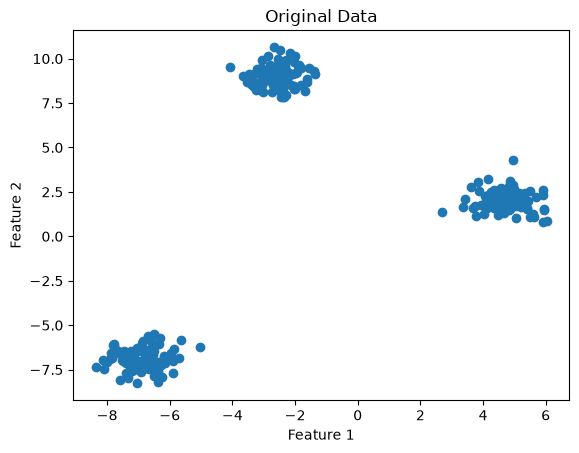

In [9]:
# 데이터 시각화
plt.scatter(X[:, 0], X[:, 1])

plt.title("Original Data")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.show()

In [ ]:
# K-Means 모델 학습
from sklearn.cluster import KMeans

# n_cluster=3 : 군집을 3개로 나눈다.
# n_init : K-Means 학습을 총 10번 수행하고, 그 중 가장 좋은 결과를 선택한다.
model = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

model.fit(X)

# 결과 확인
# labels_는 학습 데이터 각각이 어떤 군집에 할당되었는지를 나타내는 배열이다.
labels = model.labels_
print(labels[:20])

[1 1 0 2 1 2 0 2 0 0 0 2 0 0 1 0 1 2 0 0]


---
#### 실습문제

In [17]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

X, y = make_blobs(
    n_samples=400,
    centers=4,
    cluster_std=0.7,
    random_state=42
)

# 7. 전체 데이터의 shape 출력
print(X.shape)

# 8. 처음 10개의 데이터 출력
print(X[:10])

# 10. KMeans 모델 생성
# n_clusters=4
# random_state=42
# n_init=10
model = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

# 11. 모델 학습
model.fit(X)

# 12. labels_를 이용해 군집화 결과 출력
print(model.labels_)

# 14. np.unique()를 이용해 생성된 군집 종류 확인
print(np.unique(model.labels_))

# 15. 각 군집에 속하는 데이터 개수 확인
print(np.unique(model.labels_, return_counts=True))

# 16. 지도학습과 비지도학습의 가장 큰 차이는 무엇일까?
# -> 지도학습은 입력변수와 정답을 함께 모델 학습시키는 방법이고, 비지도학습은 정답없이 입력변수만으로 모델을 학습시킨다.

# 17. Classification과 Clustering의 차이는 무엇일까?
# -> 분류는 정답과 함께 모델을 학습시켜 다음 데이터의 클래스 예측이라면, 군집화는 데이터의 분류가 목적이다.

# 18. 군집화에서 model.fit(X, y)가 아닌 model.fit(X)를 사용하는 이유는 무엇일까?
# -> 군집화는 비지도학습이라 정답없이 학습을 진행한다.

# 19. 거리 기반 군집화에서 데이터 표준화가 필요한 이유는 무엇일까?
# -> 데이터간 거리를 기반으로 군집을 나누기 때문에 스케일링이 필요하다.

# 20. 군집의 개수를 지나치게 많거나 적게 설정하면 어떤 문제가 발생할까?
# -> 공통된 특성의 데이터가 다른 그룹으로 묶이거나, 다른 특성의 데이터가 같은 그룹으로 묶일 수 있다.

# 21. Cluster ID가 0인 데이터보다 2인 데이터가 더 높은 등급의 데이터라고 판단해도 될까?
# -> 데이터의 등급은 없고 단순이 그룹을 나누는것이다.

(400, 2)
[[-9.7346283   8.55187884]
 [-4.3430192   9.58961788]
 [-9.0103479   7.13261642]
 [ 5.32246265  1.87022952]
 [ 5.03950219  2.76806563]
 [-3.05747493  8.78884307]
 [-2.17793129  8.96330589]
 [-8.47596644  6.81550225]
 [-2.44826468  8.80498098]
 [ 5.65567936  2.64465926]]
[1 3 1 0 0 3 3 1 3 0 1 0 1 0 2 2 2 3 0 2 0 1 3 0 3 1 2 3 2 1 1 0 1 1 3 2 0
 0 3 2 3 1 1 2 0 0 3 2 3 0 3 1 2 0 0 1 0 3 1 0 2 0 1 2 3 3 2 2 2 1 3 2 1 0
 1 3 1 2 3 3 2 3 1 1 2 0 1 2 3 2 0 3 1 2 0 1 1 2 2 3 2 0 3 2 2 2 0 2 0 3 3
 1 0 0 1 1 1 0 1 3 2 0 1 3 1 2 2 0 2 3 3 3 2 1 2 1 3 2 3 2 3 2 2 0 3 1 2 3
 1 0 1 3 2 0 2 3 0 3 0 3 0 3 0 1 0 1 2 1 1 1 1 3 2 2 2 0 0 3 0 1 2 0 0 0 2
 0 3 3 2 2 0 1 1 0 2 2 1 2 1 1 0 3 2 3 3 0 1 3 1 2 3 0 0 3 0 2 2 0 3 0 2 3
 3 0 2 3 2 3 2 3 2 3 0 1 1 2 1 1 0 2 3 3 1 3 2 2 0 3 0 0 0 0 3 2 0 2 3 0 1
 1 3 0 0 1 1 2 2 2 3 0 0 2 2 0 3 2 3 3 0 1 3 0 2 1 3 3 1 1 1 0 0 1 0 0 2 1
 3 3 0 1 1 0 1 2 0 1 0 1 1 3 3 3 1 2 3 3 2 3 2 2 2 2 1 1 0 2 1 3 0 3 3 2 3
 0 1 2 1 3 3 1 1 2 0 3 1 0 0 1 1 3 0 0 1 0 1 